# Text Summarization - Luhn algorithm

- https://courses.ischool.berkeley.edu/i256/f06/papers/luhn58.pdf

# Preparing the environment

In [1]:
import re
import nltk
import string
import heapq

In [2]:
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /Users/ankit/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /Users/ankit/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [3]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /Users/ankit/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [4]:
original_text = """Artificial intelligence is human like intelligence machines.
                   It is the study of intelligent artificial agents.
                   Science and engineering to produce intelligent machines.
                   Solve problems and have intelligence.
                   Related to intelligent behavior machines.
                   Developing of reasoning machines.
                   Learn from mistakes and successes.
                   Artificial intelligence is related to reasoning in everyday situations."""
original_text = re.sub(r'\s+', ' ', original_text)
original_text

'Artificial intelligence is human like intelligence machines. It is the study of intelligent artificial agents. Science and engineering to produce intelligent machines. Solve problems and have intelligence. Related to intelligent behavior machines. Developing of reasoning machines. Learn from mistakes and successes. Artificial intelligence is related to reasoning in everyday situations.'

In [5]:
stopwords = nltk.corpus.stopwords.words('english')
print(stopwords)

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

In [6]:
stopwords.append('explanation')

In [7]:
print(stopwords)

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

In [8]:
def preprocess(text):
  formatted_text = text.lower()
  tokens = []
  for token in nltk.word_tokenize(formatted_text):
    tokens.append(token)
  tokens = [word for word in tokens if word not in stopwords and word not in string.punctuation]
  formatted_text = ' '.join(element for element in tokens)

  return formatted_text

In [9]:
formatted_text = preprocess(original_text)
formatted_text

'artificial intelligence human like intelligence machines study intelligent artificial agents science engineering produce intelligent machines solve problems intelligence related intelligent behavior machines developing reasoning machines learn mistakes successes artificial intelligence related reasoning everyday situations'

# Function to calculate sentences score

In [10]:
def calculate_sentences_score(sentences, important_words, distance):
  scores = []
  important_words = set(important_words)

  for sentence_index, sentence in enumerate(sentences):
    tokens = nltk.word_tokenize(sentence.lower())
    # Include every occurrence and retain the original sentence index.
    word_index = [i for i, word in enumerate(tokens) if word in important_words]

    word_index.sort()
    #print(word_index)

    if len(word_index) == 0:
      continue

    # [0, 1, 5]
    groups_list = []
    group = [word_index[0]]
    i = 1 # 3
    while i < len(word_index): # 3
      # first execution: 1 - 0 = 1
      # second execution: 2 - 1 = 1
      if word_index[i] - word_index[i - 1] < distance:
        group.append(word_index[i])
        #print('group', group)
      else:
        groups_list.append(group[:])
        group = [word_index[i]]
        #print('group', group)
      i += 1
    groups_list.append(group)
    #print('all groups', groups_list)

    max_group_score = 0
    for g in groups_list:
      #print(g)
      important_words_in_group = len(g)
      total_words_in_group = g[-1] - g[0] + 1
      score = 1.0 * important_words_in_group**2 / total_words_in_group
      #print('group score', score)

      if score > max_group_score:
        max_group_score = score

    scores.append((max_group_score, sentence_index))

  #print('final scores', scores)
  return scores

In [11]:
test = ['a', 'b', 'c']
test.index('a')

0

In [12]:
test = [0,1,3,4,6,9]
test[-1], test[0] + 1

(9, 1)

In [13]:
3*3

9

# Function to summarize the texts

In [14]:
def summarize(text, top_n_words, distance, number_of_sentences, percentage = 0):
  original_sentences = [sentence for sentence in nltk.sent_tokenize(text)]
  #print(original_sentences)
  formatted_sentences = [preprocess(original_sentence) for original_sentence in original_sentences]
  #print(formatted_sentences)
  words = [word for sentence in formatted_sentences for word in nltk.word_tokenize(sentence)]
  #print(words)
  frequency = nltk.FreqDist(words)
  #print(frequency)
  #return frequency
  top_n_words = [word[0] for word in frequency.most_common(top_n_words)]
  #print(top_n_words)
  sentences_score = calculate_sentences_score(formatted_sentences, top_n_words, distance)
  #print(sentences_score)
  if percentage > 0:
    best_sentences = heapq.nlargest(max(1, int(len(formatted_sentences) * percentage)), sentences_score)
  else:
    best_sentences = heapq.nlargest(number_of_sentences, sentences_score)
  #print(best_sentences)
  best_sentences = [original_sentences[i] for (score, i) in best_sentences]
  #print(best_sentences)
  return original_sentences, best_sentences, sentences_score

In [15]:
original_sentences, best_sentences, sentences_score = summarize(original_text, 5, 2, 3)

In [16]:
original_sentences

['Artificial intelligence is human like intelligence machines.',
 'It is the study of intelligent artificial agents.',
 'Science and engineering to produce intelligent machines.',
 'Solve problems and have intelligence.',
 'Related to intelligent behavior machines.',
 'Developing of reasoning machines.',
 'Learn from mistakes and successes.',
 'Artificial intelligence is related to reasoning in everyday situations.']

In [17]:
best_sentences

['Artificial intelligence is related to reasoning in everyday situations.',
 'Related to intelligent behavior machines.',
 'Science and engineering to produce intelligent machines.']

In [18]:
sentences_score

[(2.0, 0), (2.0, 1), (2.0, 2), (1.0, 3), (2.0, 4), (1.0, 5), (3.0, 7)]

In [19]:
from IPython.display import HTML, display
from html import escape

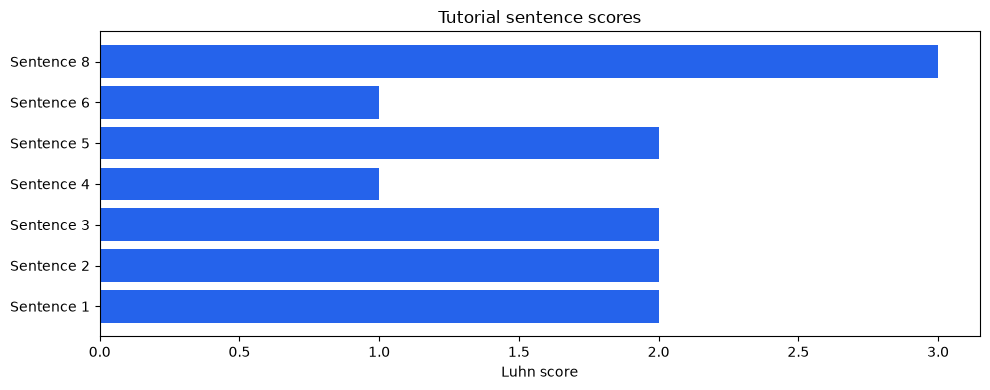

In [20]:
def visualize(title, sentence_list, best_sentences):
  selected = set(best_sentences)
  summary = ' '.join(escape(s) for s in sentence_list if s in selected)
  highlighted = ' '.join(f'<mark style="background:#fef08a;color:#111;padding:2px">{escape(s)}</mark>'
                         if s in selected else escape(s) for s in sentence_list)
  display(HTML(f'<section style="line-height:1.8;padding:18px;border:1px solid #aaa;border-radius:8px">'
               f'<h2>{escape(str(title))}</h2><h3>Extracted summary</h3><p>{summary}</p>'
               f'<details open><summary>Highlighted source text</summary><p>{highlighted}</p></details>'
               f'<p>{len(best_sentences)} of {len(sentence_list)} sentences selected</p></section>'))

visualize('Luhn algorithm — tutorial example', original_sentences, best_sentences)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh([f'Sentence {i + 1}' for _, i in sentences_score], [s for s, _ in sentences_score], color='#2563eb')
ax.set(xlabel='Luhn score', title='Tutorial sentence scores')
fig.tight_layout()
plt.show()

# Extracting texts from the Internet

In [21]:
# Dependencies are already available in the project environment.
# If needed: %pip install goose3 requests

In [22]:
from goose3 import Goose

In [23]:
from types import SimpleNamespace
import requests

g = Goose()
url = 'https://en.wikipedia.org/wiki/Automatic_summarization'
try:
  response = requests.get(url, timeout=15)
  response.raise_for_status()
  article = g.extract(raw_html=response.text)
  if not article.cleaned_text.strip():
    raise ValueError('No readable article text')
  print(f'Loaded live article: {url}')
except (requests.RequestException, ValueError) as exc:
  article = SimpleNamespace(title='Tutorial example (offline fallback)', cleaned_text=original_text)
  print(f'Live article unavailable ({type(exc).__name__}); using the tutorial text.')

Live article unavailable (HTTPError); using the tutorial text.


In [24]:
article.cleaned_text

'Artificial intelligence is human like intelligence machines. It is the study of intelligent artificial agents. Science and engineering to produce intelligent machines. Solve problems and have intelligence. Related to intelligent behavior machines. Developing of reasoning machines. Learn from mistakes and successes. Artificial intelligence is related to reasoning in everyday situations.'

In [25]:
original_sentences, best_sentences, score_sentences = summarize(article.cleaned_text, 300, 10, 120)

In [26]:
len(original_sentences)

8

In [27]:
(120 / len(original_sentences)) * 100 if original_sentences else 0

1500.0

In [28]:
original_sentences

['Artificial intelligence is human like intelligence machines.',
 'It is the study of intelligent artificial agents.',
 'Science and engineering to produce intelligent machines.',
 'Solve problems and have intelligence.',
 'Related to intelligent behavior machines.',
 'Developing of reasoning machines.',
 'Learn from mistakes and successes.',
 'Artificial intelligence is related to reasoning in everyday situations.']

In [29]:
best_sentences

['Artificial intelligence is related to reasoning in everyday situations.',
 'Artificial intelligence is human like intelligence machines.',
 'Science and engineering to produce intelligent machines.',
 'Related to intelligent behavior machines.',
 'It is the study of intelligent artificial agents.',
 'Learn from mistakes and successes.',
 'Developing of reasoning machines.',
 'Solve problems and have intelligence.']

In [30]:
score_sentences

[(6.0, 0),
 (4.0, 1),
 (5.0, 2),
 (3.0, 3),
 (4.0, 4),
 (3.0, 5),
 (3.0, 6),
 (6.0, 7)]

In [31]:
visualize(article.title, original_sentences,  best_sentences)

# Extracting articles from RSS feeds

- AI feeds: https://blog.feedspot.com/ai_rss_feeds/

In [32]:
# If needed: %pip install feedparser beautifulsoup4

In [33]:
import feedparser

In [34]:
from bs4 import BeautifulSoup
import os
import json

In [35]:
# Fetch XML explicitly: an HTML error page is not a usable RSS feed.
url = 'https://www.sciencedaily.com/rss/computers_math/artificial_intelligence.xml'
DEMO_ARTICLES = [
  {'title': 'Sample: AI research in London', 'content':
   'Researchers in London are developing artificial intelligence systems for science. '
   'The research team uses machine learning to analyze large datasets. '
   'Artificial intelligence helps researchers identify patterns and test hypotheses. '
   'The team evaluates accuracy before sharing its findings.'},
  {'title': 'Sample: Language technology in India', 'content':
   'Engineers in India are building natural language processing tools. '
   'These tools summarize documents and help readers find important information. '
   'Natural language processing combines statistical methods with machine learning. '
   'The engineers compare summaries with the original documents to check quality.'},
  {'title': 'Sample: Responsible machine learning', 'content':
   'A research group in New York studies responsible machine learning. '
   'The researchers test machine learning systems for errors and bias. '
   'Careful evaluation helps teams improve the reliability of artificial intelligence. '
   'The group documents limitations so people can interpret the results.'}
]

def entry_content(entry):
  content = entry.get('content') or []
  for item in content:
    if item.get('value', '').strip():
      return item['value']
  return entry.get('summary') or entry.get('description') or ''

try:
  response = requests.get(url, timeout=15)
  response.raise_for_status()
  feed = feedparser.parse(response.content)
  if not feed.get('version') or not feed.entries:
    raise ValueError('The response is not a populated RSS or Atom feed')
  feed.entries = [e for e in feed.entries if BeautifulSoup(entry_content(e), 'html.parser').get_text(strip=True)][:5]
  if not feed.entries:
    raise ValueError('Feed entries contain no readable text')
  feed_source = f'Live RSS feed: {url}'
except (requests.RequestException, ValueError) as exc:
  feed = feedparser.FeedParserDict(entries=[
    feedparser.FeedParserDict(title=a['title'], summary=a['content']) for a in DEMO_ARTICLES
  ])
  feed_source = 'Built-in sample articles (offline fallback; not live news)'
  print(f'Live RSS unavailable ({type(exc).__name__}).')
display(HTML(f'<h3>{escape(feed_source)}</h3><p>{len(feed.entries)} articles ready for analysis.</p>'))

In [36]:
feed.entries

[{'title': 'AI discovers a hidden heart signal that could predict sudden death',
  'title_detail': {'type': 'text/plain',
   'language': None,
   'base': '',
   'value': 'AI discovers a hidden heart signal that could predict sudden death'},
  'links': [{'rel': 'alternate',
    'type': 'text/html',
    'href': 'https://www.sciencedaily.com/releases/2026/11/261112230456.htm'}],
  'link': 'https://www.sciencedaily.com/releases/2026/11/261112230456.htm',
  'summary': 'Scientists have uncovered a hidden warning sign in routine heart scans that could predict sudden cardiac death before it strikes. The AI-powered discovery outperformed conventional screening methods, potentially revealing thousands of people at risk of a fatal heart malfunction that doctors might otherwise miss.',
  'summary_detail': {'type': 'text/html',
   'language': None,
   'base': '',
   'value': 'Scientists have uncovered a hidden warning sign in routine heart scans that could predict sudden cardiac death before it str

In [37]:
for e in feed.entries:
  print(e.get('title', 'Untitled'))
  print(entry_content(e))
  print('-------')

AI discovers a hidden heart signal that could predict sudden death
Scientists have uncovered a hidden warning sign in routine heart scans that could predict sudden cardiac death before it strikes. The AI-powered discovery outperformed conventional screening methods, potentially revealing thousands of people at risk of a fatal heart malfunction that doctors might otherwise miss.
-------
Tiny flaws in diamonds could unlock a quantum computing revolution
Scientists have discovered a faster way to identify diamond-based materials that could power quantum computers and sensors at room temperature. The breakthrough has already revealed promising new quantum building blocks that could help unlock computing capabilities far beyond those of today's supercomputers.
-------
AI-powered bionic eye breakthrough could help the blind see again
Scientists have developed an AI-powered approach that makes experimental bionic vision technology more precise, helping predict the flashes and shapes of light 

In [38]:
def clean_html(text):
  return BeautifulSoup(text or '', 'html.parser').get_text(' ', strip=True)

In [39]:
sample_content = entry_content(feed.entries[0]) if feed.entries else ''
sample_content

'Scientists have uncovered a hidden warning sign in routine heart scans that could predict sudden cardiac death before it strikes. The AI-powered discovery outperformed conventional screening methods, potentially revealing thousands of people at risk of a fatal heart malfunction that doctors might otherwise miss.'

In [40]:
clean_html(sample_content)

'Scientists have uncovered a hidden warning sign in routine heart scans that could predict sudden cardiac death before it strikes. The AI-powered discovery outperformed conventional screening methods, potentially revealing thousands of people at risk of a fatal heart malfunction that doctors might otherwise miss.'

In [41]:
articles = []
for e in feed.entries:
  articles.append({'title': e.get('title', 'Untitled'), 'content': clean_html(entry_content(e))})

In [42]:
articles

[{'title': 'AI discovers a hidden heart signal that could predict sudden death',
  'content': 'Scientists have uncovered a hidden warning sign in routine heart scans that could predict sudden cardiac death before it strikes. The AI-powered discovery outperformed conventional screening methods, potentially revealing thousands of people at risk of a fatal heart malfunction that doctors might otherwise miss.'},
 {'title': 'Tiny flaws in diamonds could unlock a quantum computing revolution',
  'content': "Scientists have discovered a faster way to identify diamond-based materials that could power quantum computers and sensors at room temperature. The breakthrough has already revealed promising new quantum building blocks that could help unlock computing capabilities far beyond those of today's supercomputers."},
 {'title': 'AI-powered bionic eye breakthrough could help the blind see again',
  'content': "Scientists have developed an AI-powered approach that makes experimental bionic vision

In [43]:
save_file = os.path.join('feed.json')
with open(save_file, 'w', encoding='utf-8') as output_file:
  json.dump(articles, output_file, indent=1, ensure_ascii=False)

In [44]:
with open('feed.json', encoding='utf-8') as input_file:
  blog_articles = json.load(input_file)
blog_articles

[{'title': 'AI discovers a hidden heart signal that could predict sudden death',
  'content': 'Scientists have uncovered a hidden warning sign in routine heart scans that could predict sudden cardiac death before it strikes. The AI-powered discovery outperformed conventional screening methods, potentially revealing thousands of people at risk of a fatal heart malfunction that doctors might otherwise miss.'},
 {'title': 'Tiny flaws in diamonds could unlock a quantum computing revolution',
  'content': "Scientists have discovered a faster way to identify diamond-based materials that could power quantum computers and sensors at room temperature. The breakthrough has already revealed promising new quantum building blocks that could help unlock computing capabilities far beyond those of today's supercomputers."},
 {'title': 'AI-powered bionic eye breakthrough could help the blind see again',
  'content': "Scientists have developed an AI-powered approach that makes experimental bionic vision

# Word cloud

In [45]:
feed_content = ' '.join(article['content'] for article in blog_articles)

In [46]:
feed_content

"Scientists have uncovered a hidden warning sign in routine heart scans that could predict sudden cardiac death before it strikes. The AI-powered discovery outperformed conventional screening methods, potentially revealing thousands of people at risk of a fatal heart malfunction that doctors might otherwise miss. Scientists have discovered a faster way to identify diamond-based materials that could power quantum computers and sensors at room temperature. The breakthrough has already revealed promising new quantum building blocks that could help unlock computing capabilities far beyond those of today's supercomputers. Scientists have developed an AI-powered approach that makes experimental bionic vision technology more precise, helping predict the flashes and shapes of light perceived by a blind man with a brain implant. By learning how an individual's brain responds to electrical stimulation, the technology could bring researchers closer to restoring some degree of sight to people with

In [47]:
formatted_feed_content = preprocess(feed_content)
formatted_feed_content

"scientists uncovered hidden warning sign routine heart scans could predict sudden cardiac death strikes ai-powered discovery outperformed conventional screening methods potentially revealing thousands people risk fatal heart malfunction doctors might otherwise miss scientists discovered faster way identify diamond-based materials could power quantum computers sensors room temperature breakthrough already revealed promising new quantum building blocks could help unlock computing capabilities far beyond today 's supercomputers scientists developed ai-powered approach makes experimental bionic vision technology precise helping predict flashes shapes light perceived blind man brain implant learning individual 's brain responds electrical stimulation technology could bring researchers closer restoring degree sight people blindness researchers created quantum computer stores information microscopic vibrations potentially making quantum machines smaller powerful better preserving information

In [48]:
len(feed_content), len(formatted_feed_content)

(1655, 1371)

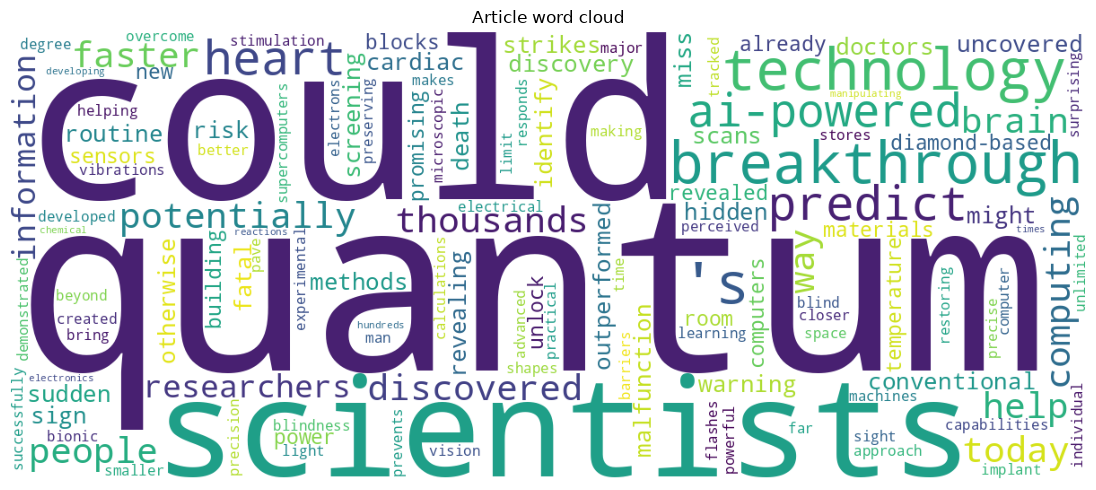

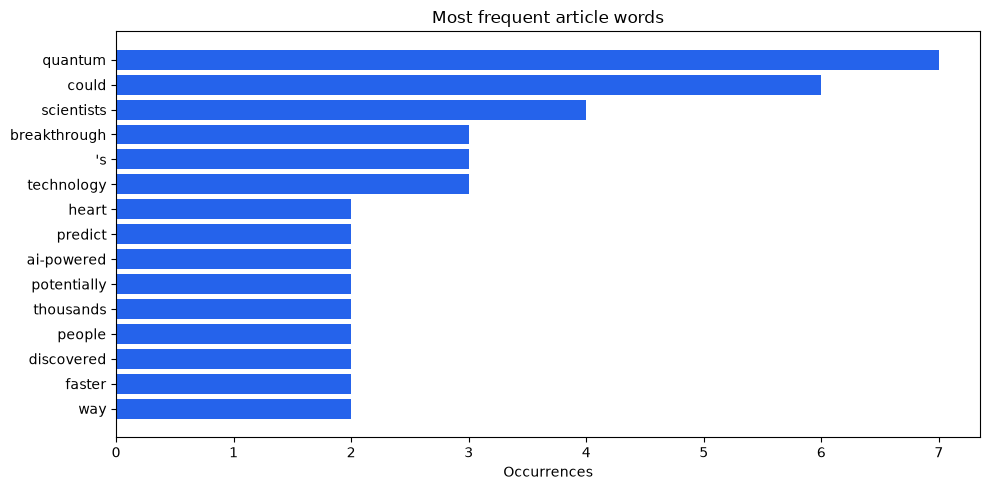

In [49]:
import matplotlib.pyplot as plt
frequency = nltk.FreqDist(nltk.word_tokenize(formatted_feed_content))
if frequency:
  try:
    from wordcloud import WordCloud
  except ImportError:
    # A word cloud is optional; still show a useful visualization without it.
    print('WordCloud is not installed; showing word frequencies. Optional: %pip install wordcloud')
  else:
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.imshow(WordCloud(width=1200, height=500, background_color='white', random_state=42).generate_from_frequencies(frequency))
    ax.set_title('Article word cloud')
    ax.axis('off')
    fig.tight_layout()
    plt.show()
  words, counts = zip(*frequency.most_common(15))
  fig, ax = plt.subplots(figsize=(10, 5))
  ax.barh(list(words)[::-1], list(counts)[::-1], color='#2563eb')
  ax.set(title='Most frequent article words', xlabel='Occurrences')
  fig.tight_layout()
  plt.show()
else:
  print('No words available for visualization.')

# Extracting named entities

- Acronyms: https://spacy.io/api/annotation#named-entities

In [50]:
# Optional statistical NER model: run in a notebook cell if required.
# import sys
# !{sys.executable} -m spacy download en_core_web_sm

In [51]:
import spacy

In [52]:
try:
  nlp = spacy.load('en_core_web_sm')
  entity_method = 'spaCy trained English model'
except OSError:
  # Explicitly labeled demonstration rules, not a trained NER replacement.
  nlp = spacy.blank('en')
  ruler = nlp.add_pipe('entity_ruler')
  ruler.add_patterns([{'label': 'GPE', 'pattern': place}
                     for place in ['London', 'India', 'New York']])
  entity_method = 'Demo place-name rules (English model not installed)'
print(entity_method)

spaCy trained English model


In [53]:
# Keep capitalization and sentence context for named entity recognition.
document = nlp(feed_content) if nlp is not None and feed_content.strip() else None

In [54]:
from spacy import displacy
if document is not None and document.ents:
  displacy.render(document, style='ent', jupyter=True)
else:
  print('No named entities to display. Check the feed content and English model.')

In [55]:
if document is not None:
  for entity in document.ents:
    if entity.label_ == 'GPE':
      print(entity.text, entity.label_)

AI GPE
AI GPE


# Saving the summary

In [56]:
from html import escape
from pathlib import Path

def save_summary(title, original_sentences, best_sentences):
  title = str(title)
  paragraphs = []
  for sentence in original_sentences:
    text = escape(sentence)
    if sentence in best_sentences:
      text = f'<mark>{text}</mark>'
    paragraphs.append(text)
  html_file = (f'<html><head><meta charset="UTF-8"><title>{escape(title)}</title>'
               f'</head><body>{" ".join(paragraphs)}</body></html>')
  # Feed titles may contain slashes or other characters invalid in filenames.
  filename = re.sub(r'[^\w .-]', '_', title).strip(' .')[:150] or 'summary'
  output_dir = Path('summaries')
  output_dir.mkdir(exist_ok=True)
  (output_dir / f'{filename}.html').write_text(html_file, encoding='utf-8')

# Summarizing the articles

In [57]:
for article in blog_articles:
  original_sentences, best_sentences, _ = summarize(article['content'], 150, 10, number_of_sentences=5, percentage=0.5)
  if not best_sentences:
    print(f"Skipping {article['title']}: no summarizable text.")
    continue
  visualize(article['title'], original_sentences, best_sentences)
  save_summary(article['title'], original_sentences, best_sentences)